In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as shc

In [8]:
import os

dataset_candidates = [
    os.path.join(os.getcwd(), "datasets", "CC_GENERAL.csv"),
    os.path.join(os.getcwd(), "datasets", "CC GENERAL.csv"),
    os.path.join(os.getcwd(), "..", "ML_Practicals", "GROUP B", "CC GENERAL.csv"),
    os.path.join(os.getcwd(), "..", "ML_Practicals", "GROUP B", "datasets", "CC GENERAL.csv"),
]

resolved = None
for candidate in dataset_candidates:
    if os.path.exists(candidate):
        resolved = candidate
        break

if resolved is None:
    raise FileNotFoundError("No CC_GENERAL dataset file was found in the expected locations.")

target_dir = os.path.join(os.getcwd(), "datasets")
os.makedirs(target_dir, exist_ok=True)
target_path = os.path.join(target_dir, "CC_GENERAL.csv")
if os.path.normcase(os.path.normpath(resolved)) != os.path.normcase(os.path.normpath(target_path)):
    import shutil
    shutil.copy2(resolved, target_path)

X = pd.read_csv(target_path)


In [9]:
# Dropping the CUST_ID column from the data
X = X.drop('CUST_ID', axis = 1)

In [10]:
# Handling the missing values
X = X.ffill()


In [11]:
# Scaling the data so that all the features become comparable
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [12]:
# Normalizing the data so that the data approximately follows a Gaussian distribution
X_normalized = normalize(X_scaled)

In [13]:
# Converting the numpy array into a pandas
DataFrameX_normalized = pd.DataFrame(X_normalized)

In [14]:
# Reducing the dimensionality of the Data
pca = PCA(n_components = 2)
X_principal = pca.fit_transform(X_normalized)
X_principal = pd.DataFrame(X_principal) 
X_principal.columns = ['P1', 'P2']

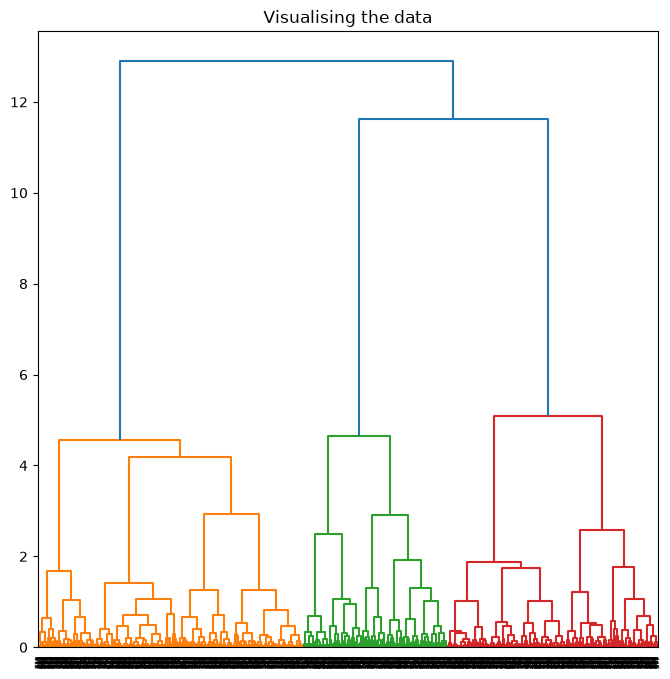

In [15]:
# Visualizing theworking of the Dendrograms
# Dendrograms are used to divide a given clusterinto many different clusters
plt.figure(figsize =(8, 8))
plt.title('Visualising the data')
Dendrogram = shc.dendrogram((shc.linkage(X_principal, method ='ward')))

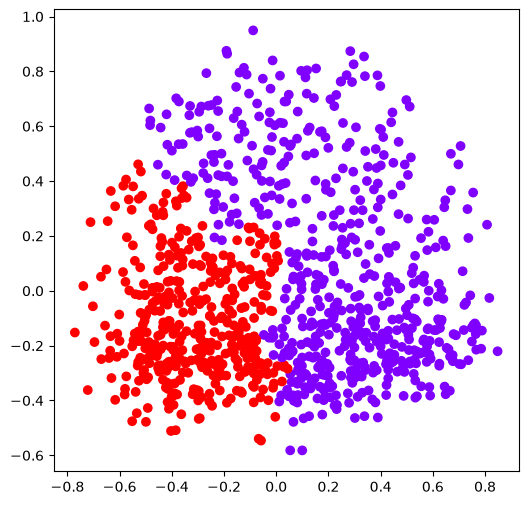

In [16]:
# Building and Visualizing the different clustering models for different values of k
# k = 2
ac2 = AgglomerativeClustering(n_clusters = 2)
plt.figure(figsize =(6, 6))
plt.scatter(X_principal['P1'], X_principal['P2'],
c = ac2.fit_predict(X_principal), cmap ='rainbow')
plt.show()

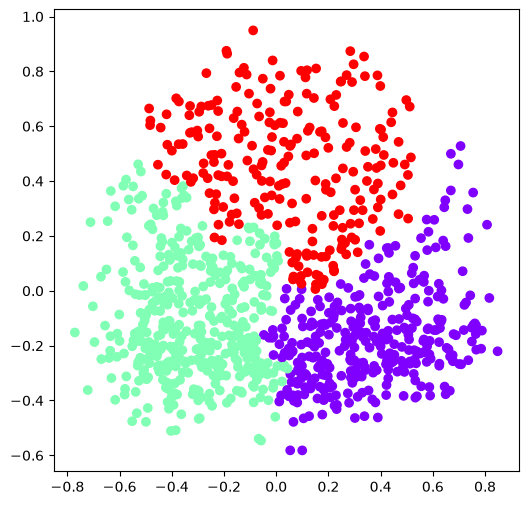

In [17]:
# k = 3
ac3 = AgglomerativeClustering(n_clusters = 3)
plt.figure(figsize =(6, 6))
plt.scatter(X_principal['P1'],
X_principal['P2'],
c = ac3.fit_predict(X_principal), cmap ='rainbow')
plt.show()

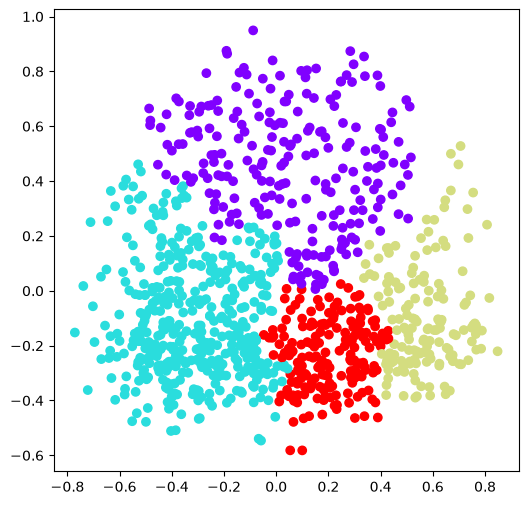

In [18]:
# k = 4
ac4 = AgglomerativeClustering(n_clusters = 4)
plt.figure(figsize =(6, 6))
plt.scatter(X_principal['P1'],
X_principal['P2'],
c = ac4.fit_predict(X_principal), cmap ='rainbow')
plt.show()

In [ ]:
# k = 5
ac5 = AgglomerativeClustering(n_clusters = 5)
plt.figure(figsize =(6, 6))
plt.scatter(X_principal['P1'],
X_principal['P2'],
c = ac5.fit_predict(X_principal), cmap ='rainbow')
plt.show()

In [ ]:
# k = 6
ac6 = AgglomerativeClustering(n_clusters = 6)
plt.figure(figsize =(6, 6))
plt.scatter(X_principal['P1'],
X_principal['P2'],
c = ac6.fit_predict(X_principal), cmap ='rainbow')
plt.show()

In [ ]:
# Evaluating the different models and Visualizing the results.
k = [2, 3, 4, 5, 6]

In [ ]:
# Appending the silhouette scores of the different models to the list
silhouette_scores = []
silhouette_scores.append(silhouette_score(X_principal, ac2.fit_predict(X_principal)))
silhouette_scores.append(silhouette_score(X_principal, ac3.fit_predict(X_principal)))
silhouette_scores.append(silhouette_score(X_principal, ac4.fit_predict(X_principal)))
silhouette_scores.append(silhouette_score(X_principal, ac5.fit_predict(X_principal)))
silhouette_scores.append(silhouette_score(X_principal, ac6.fit_predict(X_principal)))
print(silhouette_scores)

In [ ]:
# Plotting a bar graph to compare the results
plt.bar(k,silhouette_scores)
plt.xlabel('Number of Clusters', fontsize = 20)
plt.ylabel('S(i)',fontsize = 20)
plt.show()